# Неделя 05. SQL-окна и первый системный EDA

        **Кейс:** описать 35 дней работы четырёх магазинов: изменение к прошлому дню,
        скользящее среднее, накопленную выручку и разброс показателей.
        Первая половина недели завершает SQL, вторая открывает модуль EDA.
        Вся база синтетическая и доступна локально.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import sqlite3

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True,
                     "grid.alpha": 0.2, "figure.dpi": 100})

def locate_week():
    "Работает из practice/, homework/, папки недели и корня репозитория."
    current = Path.cwd().resolve()
    for parent in (current, *current.parents):
        for candidate in (parent, parent / 'week_05_sql_windows_eda'):
            if candidate.name == 'week_05_sql_windows_eda' and (candidate / "datasets").is_dir():
                return candidate
    raise FileNotFoundError("Откройте notebook внутри полного клона репозитория.")

WEEK_DIR = locate_week()
DATA_DIR = WEEK_DIR / "datasets"
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__, "| pandas:", pd.__version__)
print("Рабочая неделя:", WEEK_DIR.name)


Python: 3.12.14 | NumPy: 2.5.4 | pandas: 3.0.6
Рабочая неделя: week_05_sql_windows_eda


## 1. Контракт временной таблицы

        Окно `ROWS BETWEEN 2 PRECEDING AND CURRENT ROW` означает три строки, а не автоматически три дня.
        В этом наборе на каждый магазин есть ровно одна строка каждого дня — сначала это докажем.
        Для таблицы с пропусками календаря понадобился бы явный календарь и отдельное правило заполнения.


In [2]:
connection = sqlite3.connect((DATA_DIR / "sales.sqlite").resolve().as_uri() + "?mode=ro", uri=True)
def query(sql, params=None):
    return pd.read_sql_query(sql, connection, params=params)

sales = query("SELECT * FROM daily_sales ORDER BY store_id, sale_date")
sales["sale_date"] = pd.to_datetime(sales["sale_date"])
assert not sales.duplicated(["store_id", "sale_date"]).any()
assert len(sales) == 140
for _, group in sales.groupby("store_id"):
    expected = pd.date_range(group["sale_date"].min(), group["sale_date"].max(), freq="D")
    assert group["sale_date"].tolist() == expected.tolist()
display(sales.head())


,store_id,sale_date,orders_n,revenue_kzt,promotion
0,1,2026-04-01,42,223482,0
1,1,2026-04-02,35,185745,0
2,1,2026-04-03,34,183294,0
3,1,2026-04-04,36,161820,0
4,1,2026-04-05,55,242000,1


## 2. Окно сохраняет строки, GROUP BY сворачивает

        `SUM(revenue) OVER (PARTITION BY store_id)` добавляет итог магазина к каждой его строке.
        С ним можно вычислить долю дня в итоговой выручке магазина.
        Сумма дневных долей по магазину должна равняться 1.


In [3]:
shares = query('''
    SELECT store_id, sale_date, revenue_kzt,
           SUM(revenue_kzt) OVER (PARTITION BY store_id) AS store_total_kzt,
           1.0 * revenue_kzt / SUM(revenue_kzt) OVER (PARTITION BY store_id) AS revenue_share
    FROM daily_sales
    ORDER BY store_id, sale_date
''')
display(shares.head(7))
assert len(shares) == len(sales)
assert np.allclose(shares.groupby("store_id")["revenue_share"].sum(), 1)


,store_id,sale_date,revenue_kzt,store_total_kzt,revenue_share
0,1,2026-04-01,223482,6792406,0.032902
1,1,2026-04-02,185745,6792406,0.027346
2,1,2026-04-03,183294,6792406,0.026985
3,1,2026-04-04,161820,6792406,0.023824
4,1,2026-04-05,242000,6792406,0.035628
5,1,2026-04-06,202335,6792406,0.029788
6,1,2026-04-07,139896,6792406,0.020596


## 3. LAG: изменение к предыдущей строке

        Предыдущего дня у первой строки нет: NULL означает отсутствие сравнения, а не нулевую выручку.
        CTE `WITH previous AS (...)` позволяет сначала вычислить lag, затем использовать его в формуле.
        `NULLIF(previous, 0)` защищает от деления на ноль, если появится день с нулевой выручкой.


In [4]:
changes = query('''
    WITH previous AS (
        SELECT store_id, sale_date, revenue_kzt,
               LAG(revenue_kzt) OVER (PARTITION BY store_id ORDER BY sale_date) AS previous_revenue
        FROM daily_sales
    )
    SELECT *, revenue_kzt - previous_revenue AS change_kzt,
           100.0 * (revenue_kzt - previous_revenue) / NULLIF(previous_revenue, 0) AS change_pct
    FROM previous
    ORDER BY store_id, sale_date
''')
display(changes.head(6))
assert changes["previous_revenue"].isna().sum() == 4


,store_id,sale_date,revenue_kzt,previous_revenue,change_kzt,change_pct
0,1,2026-04-01,223482,NaN,NaN,NaN
1,1,2026-04-02,185745,223482.0,-37737.0,-16.885924
2,1,2026-04-03,183294,185745.0,-2451.0,-1.319551
3,1,2026-04-04,161820,183294.0,-21474.0,-11.715604
4,1,2026-04-05,242000,161820.0,80180.0,49.548881
5,1,2026-04-06,202335,242000.0,-39665.0,-16.390496


## 4. Скользящее и накопленное окно

        Скользящее среднее для $t\ge3$: $m_t=(x_t+x_{t-1}+x_{t-2})/3$.
        В первых двух строках используем доступные 1 или 2 наблюдения.
        Накопленная сумма $S_t=\sum_{i=1}^t x_i$ должна расти при неотрицательной выручке.
        Указываем frame явно, чтобы смысл не зависел от default `RANGE`.


In [5]:
windows = query('''
    SELECT store_id, sale_date, revenue_kzt,
           AVG(revenue_kzt) OVER (
               PARTITION BY store_id ORDER BY sale_date
               ROWS BETWEEN 2 PRECEDING AND CURRENT ROW
           ) AS rolling_3_rows,
           SUM(revenue_kzt) OVER (
               PARTITION BY store_id ORDER BY sale_date
               ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
           ) AS cumulative_revenue
    FROM daily_sales
    ORDER BY store_id, sale_date
''')
display(windows.head(6))
assert windows.groupby("store_id")["cumulative_revenue"].diff().dropna().ge(0).all()


,store_id,sale_date,revenue_kzt,rolling_3_rows,cumulative_revenue
0,1,2026-04-01,223482,223482.000000,223482
1,1,2026-04-02,185745,204613.500000,409227
2,1,2026-04-03,183294,197507.000000,592521
3,1,2026-04-04,161820,176953.000000,754341
4,1,2026-04-05,242000,195704.666667,996341
5,1,2026-04-06,202335,202051.666667,1198676


## 5. ROW_NUMBER и DENSE_RANK

        `ROW_NUMBER` нумерует строки; для выбора одной последней записи задаём однозначный порядок.
        `DENSE_RANK` даёт одинаковый ранг равным значениям без пропусков следующих рангов.
        Рейтинг выручки за день отражает объём магазина, а не его эффективность.


In [6]:
latest = query('''
    WITH ranked AS (
        SELECT *, ROW_NUMBER() OVER (PARTITION BY store_id ORDER BY sale_date DESC) AS row_n
        FROM daily_sales
    )
    SELECT store_id, sale_date, revenue_kzt FROM ranked WHERE row_n = 1 ORDER BY store_id
''')
daily_rank = query('''
    SELECT store_id, sale_date, revenue_kzt,
           DENSE_RANK() OVER (PARTITION BY sale_date ORDER BY revenue_kzt DESC) AS revenue_rank
    FROM daily_sales ORDER BY store_id, sale_date
''')
display(latest)
assert len(latest) == 4 and latest["sale_date"].nunique() == 1


,store_id,sale_date,revenue_kzt
0,1,2026-05-05,223468
1,2,2026-05-05,252050
2,3,2026-05-05,248976
3,4,2026-05-05,307533


## 6. Независимая реализация в pandas

        Сортировка и границы групп должны совпадать с SQL. `shift` — аналог LAG;
        `rolling(..., min_periods=1)` повторяет наши короткие начальные окна.
        Сравнение NaN требует `equal_nan=True`: отсутствие прошлого дня ожидаемо.


In [7]:
reference = pd.read_csv(DATA_DIR / "daily_sales.csv").sort_values(["store_id", "sale_date"]).reset_index(drop=True)
by_store = reference.groupby("store_id")["revenue_kzt"]
assert np.allclose(changes["previous_revenue"], by_store.shift(1), equal_nan=True)
rolling_ref = by_store.transform(lambda s: s.rolling(3, min_periods=1).mean())
assert np.allclose(windows["rolling_3_rows"], rolling_ref)
assert np.allclose(windows["cumulative_revenue"], by_store.cumsum())
ranks_ref = reference.groupby("sale_date")["revenue_kzt"].rank(method="dense", ascending=False)
assert np.array_equal(daily_rank["revenue_rank"], ranks_ref)
print("Проверены LAG, rolling, cumulative sum и dense rank во всех 140 строках.")


Проверены LAG, rolling, cumulative sum и dense rank во всех 140 строках.


## 7. EDA: центр, разброс и форма распределения

        Среднее описывает центр, стандартное отклонение — разброс вокруг среднего:
        $s=\sqrt{\frac{1}{n-1}\sum_i(x_i-\bar{x})^2}$.
        IQR = Q75 − Q25 описывает среднюю половину наблюдений и меньше зависит от крайних значений.
        Коэффициент вариации $CV=s/\bar{x}$ имеет смысл для положительной величины с осмысленным нулём.
        Не превращаем описательный CV в вывод о статистической значимости.


In [8]:
summary = sales.groupby("store_id")["revenue_kzt"].agg(["size", "mean", "median", "std", "min", "max"])
quantiles = sales.groupby("store_id")["revenue_kzt"].quantile([0.25, 0.75]).unstack()
summary["iqr_kzt"] = quantiles[0.75] - quantiles[0.25]
summary["cv"] = summary["std"] / summary["mean"]
display(summary.round(2))
one_store = sales.loc[sales["store_id"].eq(1), "revenue_kzt"].to_numpy()
manual_std = np.sqrt(((one_store - one_store.mean()) ** 2).sum() / (len(one_store) - 1))
assert np.isclose(manual_std, summary.loc[1, "std"])


,size,mean,median,std,min,max,iqr_kzt,cv
store_id,,,,,,,,
1,35,194068.74,188846.0,28434.76,139896,267148,42251.5,0.15
2,35,235914.66,233240.0,38675.02,176568,319672,53694.0,0.16
3,35,257851.17,251372.0,40677.74,172848,353124,52381.5,0.16
4,35,296695.40,291256.0,42674.18,230944,379086,53758.5,0.14


## 8. Гистограмма и эмпирическая функция распределения

        Гистограмма зависит от границ интервалов. ECDF показывает долю наблюдений ≤ x
        без выбора ширины интервала. Для повторяющихся значений ступеньки накладываются;
        график всё равно представляет эмпирическое распределение.


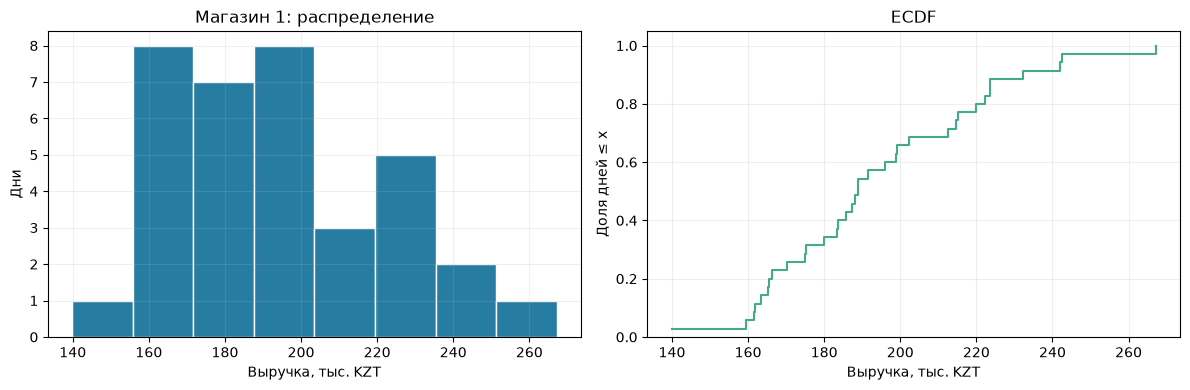

In [9]:
sorted_revenue = np.sort(one_store)
ecdf = np.arange(1, len(sorted_revenue) + 1) / len(sorted_revenue)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(one_store / 1000, bins=8, color="#277DA1", edgecolor="white")
axes[0].set(xlabel="Выручка, тыс. KZT", ylabel="Дни", title="Магазин 1: распределение")
axes[1].step(sorted_revenue / 1000, ecdf, where="post", color="#43AA8B")
axes[1].set(xlabel="Выручка, тыс. KZT", ylabel="Доля дней ≤ x", ylim=(0, 1.05), title="ECDF")
plt.tight_layout()
plt.show()
assert np.all(np.diff(ecdf) >= 0) and ecdf[-1] == 1


## 9. Сглаживание не создаёт новые наблюдения

        Сравним исходный ряд и rolling mean. Сглаживание подавляет быстрые изменения,
        но соседние точки начинают использовать общие данные. Их нельзя считать независимыми.
        Для прогноза следующего дня окно должно опираться только на прошлые значения;
        наше окно с текущим днём используется для описания уже завершённого дня.


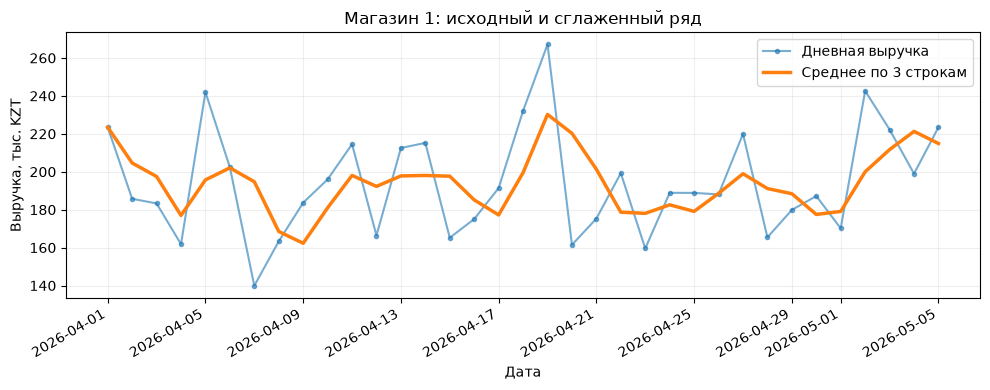

In [10]:
w = windows.loc[windows["store_id"].eq(1)].copy()
w["sale_date"] = pd.to_datetime(w["sale_date"])
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(w["sale_date"], w["revenue_kzt"] / 1000, alpha=0.6, marker=".", label="Дневная выручка")
ax.plot(w["sale_date"], w["rolling_3_rows"] / 1000, linewidth=2.5, label="Среднее по 3 строкам")
ax.set(xlabel="Дата", ylabel="Выручка, тыс. KZT", title="Магазин 1: исходный и сглаженный ряд")
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


## 10. Средний чек: правильное взвешивание

        Среднее дневных средних чеков придаёт одинаковый вес дню с 10 и 100 заказами.
        Средний чек всех заказов за период равен суммарной выручке / числу заказов.
        Число дней и число заказов — разные единицы наблюдения.


In [11]:
sales["daily_mean_ticket"] = sales["revenue_kzt"] / sales["orders_n"]
ticket_report = sales.groupby("store_id").agg(
    revenue=("revenue_kzt", "sum"), orders=("orders_n", "sum"),
    mean_of_daily_means=("daily_mean_ticket", "mean"))
ticket_report["weighted_mean_ticket"] = ticket_report["revenue"] / ticket_report["orders"]
display(ticket_report.round(2))
for store_id, group in sales.groupby("store_id"):
    assert np.isclose(np.average(group["daily_mean_ticket"], weights=group["orders_n"]),
                      ticket_report.loc[store_id, "weighted_mean_ticket"])
connection.close()


,revenue,orders,mean_of_daily_means,weighted_mean_ticket
store_id,,,,
1,6792406,1493,4579.26,4549.50
2,8257013,1737,4754.74,4753.61
3,9024791,1874,4819.66,4815.79
4,10384339,2117,4913.74,4905.21


## Короткий итог для аналитика

        Укажите магазин с максимальной суммой, магазин с максимальной вариативностью,
        и почему это могут быть разные магазины. Объясните, почему нельзя объявить
        акцию причиной роста только по группировке `promotion`.

        Домашняя работа: [Homework Week 05](../homework/Homework_Week_05.md).


## Документация и дальнейшее чтение

- [SQLite: оконные функции](https://www.sqlite.org/windowfunctions.html)
- [pandas: rolling](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.rolling.html)
- [NumPy: standard deviation](https://numpy.org/doc/stable/reference/generated/numpy.std.html)

Код, объяснения и синтетические примеры в этой лабораторной подготовлены для курса; это не копия университетского ноутбука. Дополнительные лекции находятся в `../presentations/`. Документация проверена 18 октября 2026 года; версии среды закреплены на уровне репозитория.
